# Part 1: Data Cleaning and Exploratory Data Analysis (EDA)

In this notebook, we will:
- Load the dataset
- Explore the dataset
- Check missing values
- Understand numerical and categorical features
- Perform basic data cleaning

In [2]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully.")

All libraries imported successfully.


In [3]:
df = pd.read_csv("../data/train.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [4]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
print("Shape of Dataset:", df.shape)

print("\nData Types:\n")
print(df.dtypes)

Shape of Dataset: (1460, 81)

Data Types:

Id                 int64
MSSubClass         int64
MSZoning          object
LotFrontage      float64
LotArea            int64
                  ...   
MoSold             int64
YrSold             int64
SaleType          object
SaleCondition     object
SalePrice          int64
Length: 81, dtype: object


In [6]:
missing_values = df.isnull().sum()

print(missing_values)

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64


In [7]:
missing_percentage = (df.isnull().sum() / df.shape[0]) * 100

print(missing_percentage)

Id                0.000000
MSSubClass        0.000000
MSZoning          0.000000
LotFrontage      17.739726
LotArea           0.000000
                   ...    
MoSold            0.000000
YrSold            0.000000
SaleType          0.000000
SaleCondition     0.000000
SalePrice         0.000000
Length: 81, dtype: float64


In [8]:
missing_data = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

print(missing_data)

               Missing Values  Missing Percentage
Id                          0            0.000000
MSSubClass                  0            0.000000
MSZoning                    0            0.000000
LotFrontage               259           17.739726
LotArea                     0            0.000000
...                       ...                 ...
MoSold                      0            0.000000
YrSold                      0            0.000000
SaleType                    0            0.000000
SaleCondition               0            0.000000
SalePrice                   0            0.000000

[81 rows x 2 columns]


In [9]:
more_than_20 = missing_data[missing_data["Missing Percentage"] > 20]

more_than_20

,Missing Values,Missing Percentage
Alley,1369,93.767123
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
PoolQC,1453,99.520548
Fence,1179,80.753425
MiscFeature,1406,96.301370


In [10]:
numeric_columns = df.select_dtypes(include=["number"]).columns

for column in numeric_columns:
    if df[column].isnull().sum() > 0:
        missing_percent = (df[column].isnull().sum() / len(df)) * 100

        if missing_percent < 20:
            median_value = df[column].median()
            df[column] = df[column].fillna(median_value)

In [11]:
df[numeric_columns].isnull().sum()

Id               0
MSSubClass       0
LotFrontage      0
LotArea          0
OverallQual      0
OverallCond      0
YearBuilt        0
YearRemodAdd     0
MasVnrArea       0
BsmtFinSF1       0
BsmtFinSF2       0
BsmtUnfSF        0
TotalBsmtSF      0
1stFlrSF         0
2ndFlrSF         0
LowQualFinSF     0
GrLivArea        0
BsmtFullBath     0
BsmtHalfBath     0
FullBath         0
HalfBath         0
BedroomAbvGr     0
KitchenAbvGr     0
TotRmsAbvGrd     0
Fireplaces       0
GarageYrBlt      0
GarageCars       0
GarageArea       0
WoodDeckSF       0
OpenPorchSF      0
EnclosedPorch    0
3SsnPorch        0
ScreenPorch      0
PoolArea         0
MiscVal          0
MoSold           0
YrSold           0
SalePrice        0
dtype: int64

In [12]:
print(df.isnull().sum())

Id               0
MSSubClass       0
MSZoning         0
LotFrontage      0
LotArea          0
                ..
MoSold           0
YrSold           0
SaleType         0
SaleCondition    0
SalePrice        0
Length: 81, dtype: int64


In [13]:
numeric_data = df.select_dtypes(include=["number"])

In [14]:
outlier_count = {}

for column in numeric_data.columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_limit) | (df[column] > upper_limit)]

    outlier_count[column] = len(outliers)

In [15]:
outlier_df = pd.DataFrame(
    outlier_count.items(),
    columns=["Column", "Outlier Count"]
)

outlier_df

,Column,Outlier Count
0,Id,0
1,MSSubClass,103
2,LotFrontage,106
3,LotArea,69
4,OverallQual,2
5,OverallCond,125
6,YearBuilt,7
7,YearRemodAdd,0
8,MasVnrArea,98
9,BsmtFinSF1,7


In [16]:
outlier_df[outlier_df["Outlier Count"] > 0]

,Column,Outlier Count
1,MSSubClass,103
2,LotFrontage,106
3,LotArea,69
4,OverallQual,2
5,OverallCond,125
6,YearBuilt,7
8,MasVnrArea,98
9,BsmtFinSF1,7
10,BsmtFinSF2,167
11,BsmtUnfSF,29


In [17]:
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns

categorical_columns = df.select_dtypes(include=["object"]).columns

print("Number of Numerical Columns:", len(numerical_columns))
print("Number of Categorical Columns:", len(categorical_columns))

Number of Numerical Columns: 38
Number of Categorical Columns: 43


In [18]:
print("Numerical Columns:\n")
print(numerical_columns)

print("\nCategorical Columns:\n")
print(categorical_columns)

Numerical Columns:

Index(['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='object')

Categorical Columns:

Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFin

## Duplicate Values

In [19]:
# Create a copy before removing duplicates
df_before = df.copy()

rows_before = len(df)

duplicate_rows = df.duplicated().sum()

print("Duplicate Rows:", duplicate_rows)

df = df.drop_duplicates()

rows_after = len(df)

print("Rows Removed:", rows_before - rows_after)
print("New Shape:", df.shape)

Duplicate Rows: 0
Rows Removed: 0
New Shape: (1460, 81)


In [54]:
missing_before = (df_before.isnull().sum() / len(df_before)) * 100

missing_after = (df.isnull().sum() / len(df)) * 100

comparison = pd.DataFrame({
    "Before (%)": missing_before,
    "After (%)": missing_after,
    "Difference": missing_after - missing_before
})

print("Missing Percentage Comparison")
comparison

Missing Percentage Comparison


,Before (%),After (%),Difference
Id,0.0,0.0,0.0
MSSubClass,0.0,0.0,0.0
MSZoning,0.0,0.0,0.0
LotFrontage,0.0,0.0,0.0
LotArea,0.0,0.0,0.0
...,...,...,...
MoSold,0.0,0.0,0.0
YrSold,0.0,0.0,0.0
SaleType,0.0,0.0,0.0
SaleCondition,0.0,0.0,0.0


## Data Type Conversion

In [22]:
memory_before = df.memory_usage(deep=True).sum()

print("Memory Before:", memory_before)

Memory Before: 3600842


In [23]:
df["Neighborhood"] = df["Neighborhood"].astype("category")

In [24]:
memory_after = df.memory_usage(deep=True).sum()

print("Memory After:", memory_after)

Memory After: 3523227


In [25]:
print("Memory Reduced:", memory_before - memory_after, "bytes")

Memory Reduced: 77615 bytes


In [56]:
# Checking whether any numeric column is incorrectly stored as object
object_columns = df.select_dtypes(include="object").columns.tolist()

print("Object Columns:")
print(object_columns)

print("\nNo numeric column is stored as object.")
print("Only categorical columns are present as object dtype.")

Object Columns:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']

No numeric column is stored as object.
Only categorical columns are present as object dtype.


In [26]:
print(df["Neighborhood"].dtype)

category


## Descriptive Statistics and Skewness

In [27]:
df.describe(include=[np.number])

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,69.863699,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.117123,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,22.027677,9981.264932,1.382997,1.112799,30.202904,20.645407,180.731373,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,60.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,79.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,164.250000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [28]:
skewness = df.select_dtypes(include=["number"]).skew()

print(skewness)

Id                0.000000
MSSubClass        1.407657
LotFrontage       2.409147
LotArea          12.207688
OverallQual       0.216944
OverallCond       0.693067
YearBuilt        -0.613461
YearRemodAdd     -0.503562
MasVnrArea        2.677616
BsmtFinSF1        1.685503
BsmtFinSF2        4.255261
BsmtUnfSF         0.920268
TotalBsmtSF       1.524255
1stFlrSF          1.376757
2ndFlrSF          0.813030
LowQualFinSF      9.011341
GrLivArea         1.366560
BsmtFullBath      0.596067
BsmtHalfBath      4.103403
FullBath          0.036562
HalfBath          0.675897
BedroomAbvGr      0.211790
KitchenAbvGr      4.488397
TotRmsAbvGrd      0.676341
Fireplaces        0.649565
GarageYrBlt      -0.678333
GarageCars       -0.342549
GarageArea        0.179981
WoodDeckSF        1.541376
OpenPorchSF       2.364342
EnclosedPorch     3.089872
3SsnPorch        10.304342
ScreenPorch       4.122214
PoolArea         14.828374
MiscVal          24.476794
MoSold            0.212053
YrSold            0.096269
S

In [29]:
highest_skew = skewness.abs().idxmax()

print("Column with Highest Skewness:", highest_skew)
print("Skewness Value:", skewness[highest_skew])

Column with Highest Skewness: MiscVal
Skewness Value: 24.476794188821916


In [30]:
print(skewness.sort_values(key=abs, ascending=False))

MiscVal          24.476794
PoolArea         14.828374
LotArea          12.207688
3SsnPorch        10.304342
LowQualFinSF      9.011341
KitchenAbvGr      4.488397
BsmtFinSF2        4.255261
ScreenPorch       4.122214
BsmtHalfBath      4.103403
EnclosedPorch     3.089872
MasVnrArea        2.677616
LotFrontage       2.409147
OpenPorchSF       2.364342
SalePrice         1.882876
BsmtFinSF1        1.685503
WoodDeckSF        1.541376
TotalBsmtSF       1.524255
MSSubClass        1.407657
1stFlrSF          1.376757
GrLivArea         1.366560
BsmtUnfSF         0.920268
2ndFlrSF          0.813030
OverallCond       0.693067
GarageYrBlt      -0.678333
TotRmsAbvGrd      0.676341
HalfBath          0.675897
Fireplaces        0.649565
YearBuilt        -0.613461
BsmtFullBath      0.596067
YearRemodAdd     -0.503562
GarageCars       -0.342549
OverallQual       0.216944
MoSold            0.212053
BedroomAbvGr      0.211790
GarageArea        0.179981
YrSold            0.096269
FullBath          0.036562
I

In [31]:
skew_table = pd.DataFrame({
    "Column": skewness.index,
    "Skewness": skewness.values
})

skew_table

,Column,Skewness
0,Id,0.000000
1,MSSubClass,1.407657
2,LotFrontage,2.409147
3,LotArea,12.207688
4,OverallQual,0.216944
5,OverallCond,0.693067
6,YearBuilt,-0.613461
7,YearRemodAdd,-0.503562
8,MasVnrArea,2.677616
9,BsmtFinSF1,1.685503


## Line Plot

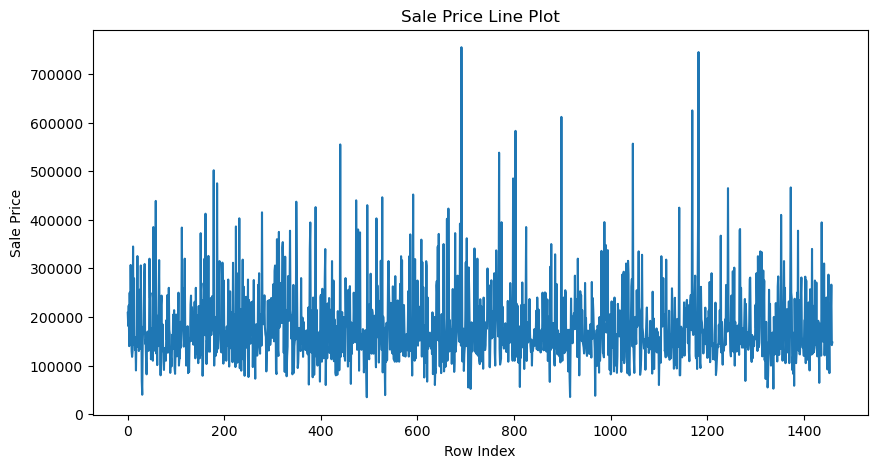

In [32]:
plt.figure(figsize=(10,5))

plt.plot(df.index, df["SalePrice"])

plt.title("Sale Price Line Plot")
plt.xlabel("Row Index")
plt.ylabel("Sale Price")

plt.show()

## Bar Chart

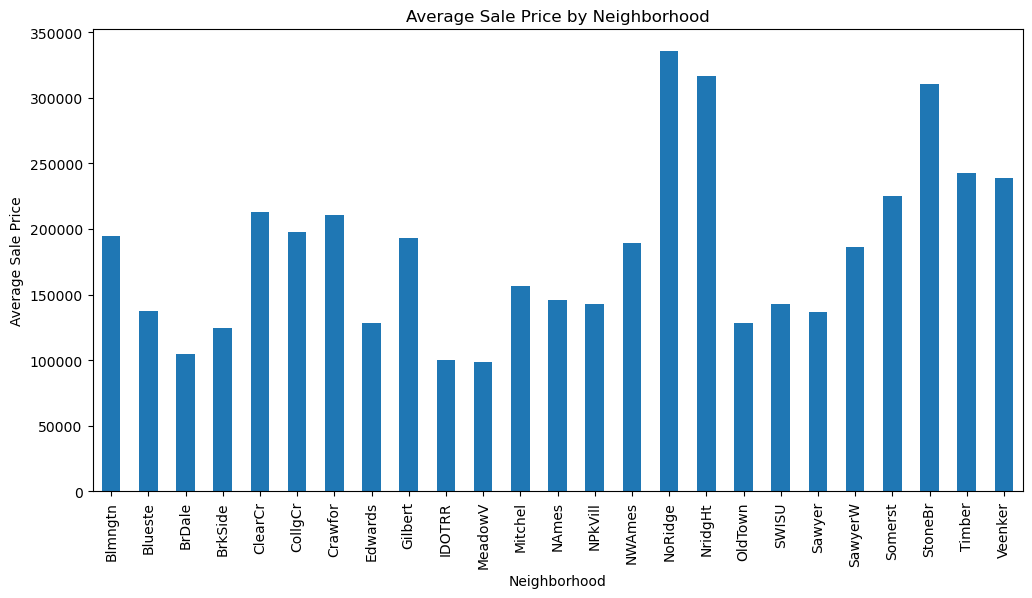

In [33]:
average_price = df.groupby("Neighborhood", observed=False)["SalePrice"].mean()

plt.figure(figsize=(12,6))

average_price.plot(kind="bar")

plt.title("Average Sale Price by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Average Sale Price")

plt.xticks(rotation=90)

plt.show()

## Histogram

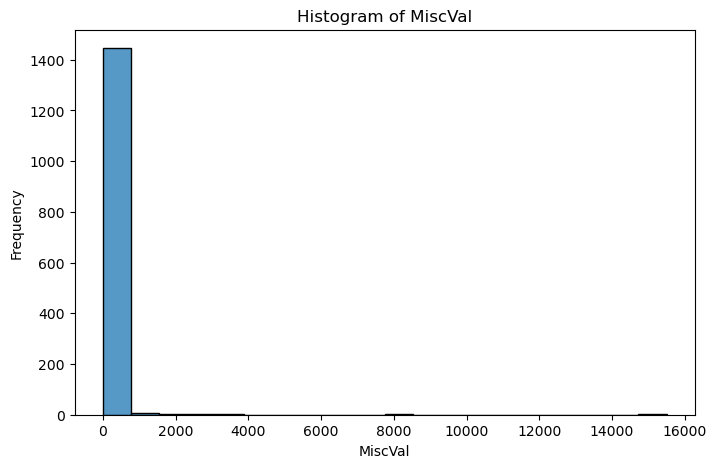

In [34]:
plt.figure(figsize=(8,5))

sns.histplot(df[highest_skew], bins=20)

plt.title(f"Histogram of {highest_skew}")
plt.xlabel(highest_skew)
plt.ylabel("Frequency")

plt.show()

## Scatter Plot

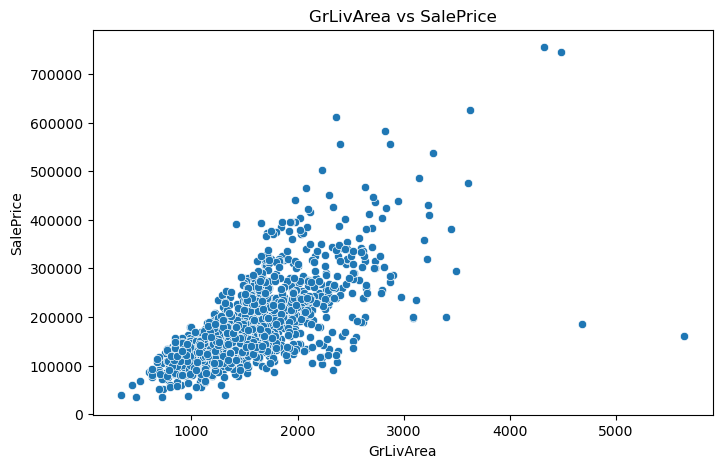

In [35]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=df,
                x="GrLivArea",
                y="SalePrice")

plt.title("GrLivArea vs SalePrice")

plt.show()

## Box Plot

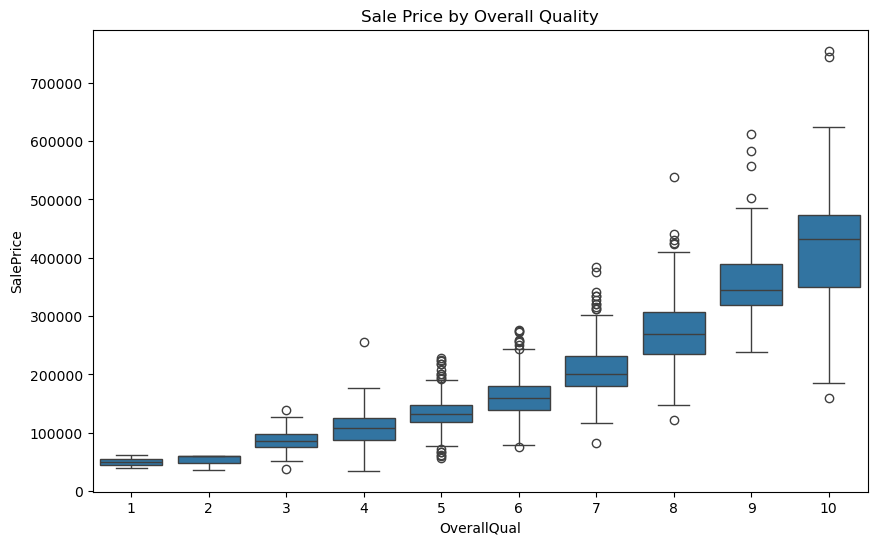

In [36]:
plt.figure(figsize=(10,6))

sns.boxplot(data=df,
            x="OverallQual",
            y="SalePrice")

plt.title("Sale Price by Overall Quality")

plt.show()

## Correlation Heatmap

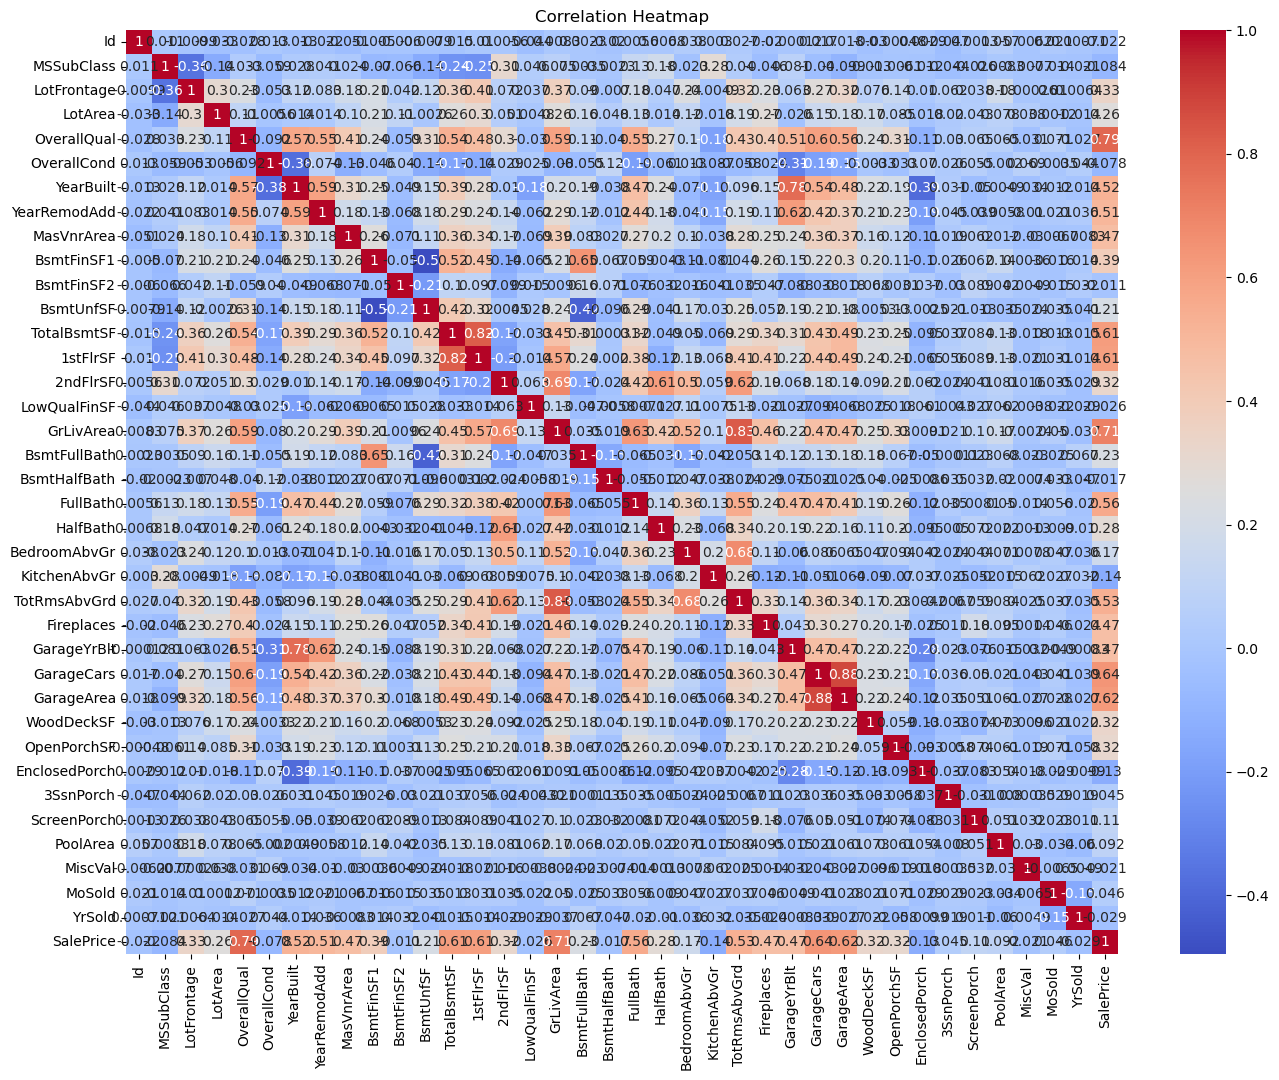

In [37]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(16, 12))

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

In [38]:
correlation_pairs = correlation_matrix.abs().unstack()

correlation_pairs = correlation_pairs.sort_values(ascending=False)

correlation_pairs = correlation_pairs[correlation_pairs < 1]

print(correlation_pairs.head(10))

GarageArea    GarageCars      0.882475
GarageCars    GarageArea      0.882475
GrLivArea     TotRmsAbvGrd    0.825489
TotRmsAbvGrd  GrLivArea       0.825489
TotalBsmtSF   1stFlrSF        0.819530
1stFlrSF      TotalBsmtSF     0.819530
OverallQual   SalePrice       0.790982
SalePrice     OverallQual     0.790982
YearBuilt     GarageYrBlt     0.777182
GarageYrBlt   YearBuilt       0.777182
dtype: float64


## IQR Analysis (Two Numeric Columns)

In [39]:
columns = ["SalePrice", "GrLivArea"]

for column in columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower) | (df[column] > upper)]

    print("\nColumn:", column)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Outliers:", len(outliers))


Column: SalePrice
Q1: 129975.0
Q3: 214000.0
IQR: 84025.0
Outliers: 61

Column: GrLivArea
Q1: 1129.5
Q3: 1776.75
IQR: 647.25
Outliers: 31


In [40]:
print("Lower Bound:", lower)
print("Upper Bound:", upper)

Lower Bound: 158.625
Upper Bound: 2747.625


## Mean and Median Comparison

In [41]:
highest_skew = skewness.abs().sort_values(ascending=False)

top_columns = highest_skew.index[:2]

print(top_columns)

Index(['MiscVal', 'PoolArea'], dtype='object')


In [42]:
for column in top_columns:
    print("\nColumn:", column)
    print("Mean:", df[column].mean())
    print("Median:", df[column].median())


Column: MiscVal
Mean: 43.489041095890414
Median: 0.0

Column: PoolArea
Mean: 2.758904109589041
Median: 0.0


In [43]:
print("Missing Values After Cleaning:")
print(df[top_columns].isnull().sum())

Missing Values After Cleaning:
MiscVal     0
PoolArea    0
dtype: int64


In [44]:
print("Total Missing Values in Dataset:")
print(df.isnull().sum().sum())

Total Missing Values in Dataset:
7481


## Spearman Correlation

In [45]:
pearson_corr = df.corr(numeric_only=True, method="pearson")

spearman_corr = df.corr(numeric_only=True, method="spearman")

print("Pearson Correlation Matrix")
print(pearson_corr)

print("\nSpearman Correlation Matrix")
print(spearman_corr)

Pearson Correlation Matrix
                     Id  MSSubClass  LotFrontage   LotArea  OverallQual  \
Id             1.000000    0.011156    -0.009921 -0.033226    -0.028365   
MSSubClass     0.011156    1.000000    -0.356718 -0.139781     0.032628   
LotFrontage   -0.009921   -0.356718     1.000000  0.304522     0.234812   
LotArea       -0.033226   -0.139781     0.304522  1.000000     0.105806   
OverallQual   -0.028365    0.032628     0.234812  0.105806     1.000000   
OverallCond    0.012609   -0.059316    -0.053281 -0.005636    -0.091932   
YearBuilt     -0.012713    0.027850     0.116685  0.014228     0.572323   
YearRemodAdd  -0.021998    0.040581     0.083348  0.013788     0.550684   
MasVnrArea    -0.051071    0.023573     0.178469  0.103321     0.407252   
BsmtFinSF1    -0.005024   -0.069836     0.214367  0.214103     0.239666   
BsmtFinSF2    -0.005968   -0.065649     0.042463  0.111170    -0.059119   
BsmtUnfSF     -0.007940   -0.140759     0.124098 -0.002618     0.308159  

In [46]:
pearson_saleprice = pearson_corr["SalePrice"].sort_values(ascending=False)

spearman_saleprice = spearman_corr["SalePrice"].sort_values(ascending=False)

print("Pearson Correlation with SalePrice")
print(pearson_saleprice)

print("\nSpearman Correlation with SalePrice")
print(spearman_saleprice)

Pearson Correlation with SalePrice
SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
MasVnrArea       0.472614
Fireplaces       0.466929
GarageYrBlt      0.466754
BsmtFinSF1       0.386420
LotFrontage      0.334771
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
Kit

In [47]:
comparison = pd.DataFrame({
    "Pearson": pearson_saleprice,
    "Spearman": spearman_saleprice
})

print(comparison.head(10))

                Pearson  Spearman
1stFlrSF       0.605852  0.575408
2ndFlrSF       0.319334  0.293598
3SsnPorch      0.044584  0.065440
BedroomAbvGr   0.168213  0.234907
BsmtFinSF1     0.386420  0.301871
BsmtFinSF2    -0.011378 -0.038806
BsmtFullBath   0.227122  0.225125
BsmtHalfBath  -0.016844 -0.012189
BsmtUnfSF      0.214479  0.185197
EnclosedPorch -0.128578 -0.218394


In [48]:
print("Observation:")
print("Pearson measures linear relationship.")
print("Spearman measures rank-based relationship.")
print("Both methods show that OverallQual and GrLivArea are highly related to SalePrice.")

Observation:
Pearson measures linear relationship.
Spearman measures rank-based relationship.
Both methods show that OverallQual and GrLivArea are highly related to SalePrice.


## Grouped Aggregation

In [49]:
group_result = df.groupby(
    "Neighborhood",
    observed=False
)["SalePrice"].agg(["mean", "std", "count"])

group_result

,mean,std,count
Neighborhood,,,
Blmngtn,194870.882353,30393.229219,17
Blueste,137500.000000,19091.883092,2
BrDale,104493.750000,14330.176493,16
BrkSide,124834.051724,40348.689270,58
ClearCr,212565.428571,50231.538993,28
CollgCr,197965.773333,51403.666438,150
Crawfor,210624.725490,68866.395472,51
Edwards,128219.700000,43208.616459,100
Gilbert,192854.506329,35986.779085,79


In [50]:
print("Highest Mean Group:")
print(group_result["mean"].idxmax())

print("\nHighest Standard Deviation Group:")
print(group_result["std"].idxmax())

Highest Mean Group:
NoRidge

Highest Standard Deviation Group:
NoRidge


In [51]:
highest_mean = group_result["mean"].max()

lowest_mean = group_result["mean"].min()

ratio = highest_mean / lowest_mean

print("Mean Ratio:", ratio)

Mean Ratio: 3.4013727116863004


In [52]:
print("Highest Mean:", highest_mean)

print("Lowest Mean:", lowest_mean)

print("Mean Ratio:", ratio)

Highest Mean: 335295.31707317074
Lowest Mean: 98576.4705882353
Mean Ratio: 3.4013727116863004


## Save Cleaned Dataset

In [53]:
df.to_csv("../data/cleaned_data.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.
